# Solutions to the exercises of Chapter 10

Sample solutions for [Chapter 10, Diffusion and sedimentation of colloids](../../notebooks/part3_soft_materials/10_diffusion_sedimentation.ipynb).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

def osmotic_cs(p):
    return p * (1 + p + p**2 - p**3) / (1 - p) ** 3

def d_osmotic_cs(p):
    return (1 + 4 * p + 4 * p**2 - 4 * p**3 + p**4) / (1 - p) ** 4

## Exercise 1. The ultracentrifuge

In a frame rotating with the rotor, a particle feels the centrifugal force
$m_b\omega^2r$ outwards, where $m_b = v_c\Delta\rho$ is its buoyant mass. This replaces the
weight in Eq. (10.1), with $-\tfrac12m_b\omega^2r^2$ per particle as the potential energy.
In equilibrium Eq. (10.7) becomes $d\Pi/dr = n\,m_b\omega^2r$, and for a dilute solution,
$\Pi = nk_BT$,

$$ \frac{d\ln c}{dr} = \frac{m_b\omega^2r}{k_BT} \quad\Longrightarrow\quad c(r) \propto \exp\Big(\frac{m_b\omega^2r^2}{2k_BT}\Big) . $$

A plot of $\ln c$ against $r^2$ is a straight line of slope $m_b\omega^2/2k_BT$, which gives the
buoyant mass, and with the partial specific volume $\bar v$ the molar mass:
$m_b = (M/N_A)(1 - \bar v\rho_s)$. This is how the molar masses of proteins have been
measured since Svedberg.

In [2]:
kT, NA = 1.380649e-23 * 293.15, 6.02214076e23
M, vbar, rho_s = 66.0, 0.73e-3, 998.2                     # kg/mol, m^3/kg, kg/m^3
m_b = M / NA * (1 - vbar * rho_s)
omega = 12000 * 2 * math.pi / 60
r1, r2 = 0.065, 0.070
exponent = m_b * omega**2 * (r2**2 - r1**2) / (2 * kT)
print(f"buoyant mass {m_b:.3e} kg;  omega = {omega:.0f} rad/s")
print(f"c(7.0 cm) / c(6.5 cm) = exp({exponent:.3f}) = {math.exp(exponent):.1f}")
print(f"the same field as gravity times {omega**2 * 0.0675 / 9.81:.0f}; gravitational length at 6.75 cm: {kT / (m_b * omega**2 * 0.0675) * 1e3:.2f} mm")
print(f"gravitational length under gravity alone: {kT / (m_b * 9.81):.0f} m")

buoyant mass 2.973e-23 kg;  omega = 1257 rad/s
c(7.0 cm) / c(6.5 cm) = exp(3.915) = 50.2
the same field as gravity times 10866; gravitational length at 6.75 cm: 1.28 mm
gravitational length under gravity alone: 14 m


The concentration rises fiftyfold across half a centimetre. Under gravity alone the
gravitational length of this protein would be about 14 m, and nothing would be seen
in a cell a centimetre high.

## Exercise 2. Batchelor's diffusion coefficient

With $\tilde\Pi = \phi + 4\phi^2 + O(\phi^3)$, $d\tilde\Pi/d\phi = 1 + 8\phi$, and Eq. (10.5) gives

$$ \frac{D_c}{D_0} = (1 - 6.55\phi)(1 + 8\phi) = 1 + 1.45\phi + O(\phi^2) , $$

Batchelor's result (1976). The Richardson–Zaki law, $K = (1 - \phi)^{4.65} \simeq 1 - 4.65\phi$,
gives $1 + 3.35\phi$: it is a fit to concentrated suspensions and is not accurate at
first order (Figure 10.1 shows the two slopes).

The two coefficients move apart because they respond to different forces. Settling
is driven by gravity, which pulls each particle with the same force whatever the
concentration, and the hydrodynamic hindrance only slows it down. Collective
diffusion is driven by the gradient of the osmotic pressure, which grows with the
concentration: crowded particles push each other apart more strongly. The
thermodynamic factor, $1 + 8\phi$, wins over the hydrodynamic one, $1 - 6.55\phi$.

In [3]:
for name, K in (("Batchelor", lambda p: 1 - 6.55 * p), ("Richardson-Zaki", lambda p: (1 - p) ** 4.65)):
    h = 1e-6
    D = lambda p: K(p) * d_osmotic_cs(p)
    print(f"{name:16s} initial slope of D_c/D0: {(D(h) - D(0)) / h:.3f}")

Batchelor        initial slope of D_c/D0: 1.450
Richardson-Zaki  initial slope of D_c/D0: 3.350


## Exercise 3. How long does equilibrium take?

(a) Near equilibrium, $b = \alpha + \delta$, the trial obeys $\zeta(\alpha)\,\dot\delta = -F''(\alpha)\,\delta$, so it
relaxes at the rate $F''(\alpha)/\zeta(\alpha)$. The cell computes it from the functions of
Section 10.3 and compares it with the exact slowest rate $\lambda_1 = \pi^2/\alpha + \alpha/4$.

In [4]:
Z = np.linspace(0, 1, 4001)

def profile(b):
    return np.ones_like(Z) if abs(b) < 1e-9 else b * np.exp(-b * Z) / -np.expm1(-b)

def trial_rate(alpha, h=1e-3):
    F = lambda b: np.trapezoid(profile(b) * (np.log(profile(b)) + alpha * Z), Z)
    d2F = (F(alpha + h) - 2 * F(alpha) + F(alpha - h)) / h**2
    E = -math.expm1(-alpha)
    j = (Z * np.exp(-alpha * Z) * E + np.expm1(-alpha * Z) * math.exp(-alpha)) / E**2   # exact flux per unit bdot
    zeta = alpha * np.trapezoid(j * j / profile(alpha), Z)
    return d2F / zeta

alphas = np.logspace(-1, 2, 25)
exact = np.pi**2 / alphas + alphas / 4
trial = np.array([trial_rate(a) for a in alphas])
for a in (0.1, 1.0, 2 * math.pi, 10.0, 100.0):
    i = np.argmin(np.abs(alphas - a))
    print(f"alpha = {alphas[i]:7.3f}:  exact lambda_1 = {exact[i]:8.3f}   trial {trial[i]:8.3f}   ratio {trial[i] / exact[i]:.4f}")

alpha =   0.100:  exact lambda_1 =   98.721   trial  100.029   ratio 1.0133
alpha =   1.000:  exact lambda_1 =   10.120   trial   10.295   ratio 1.0173
alpha =   5.623:  exact lambda_1 =    3.161   trial    3.691   ratio 1.1677
alpha =  10.000:  exact lambda_1 =    3.487   trial    5.093   ratio 1.4606
alpha = 100.000:  exact lambda_1 =   25.099   trial   50.037   ratio 1.9936


The trial's rate is never below the exact slowest rate, and this is no accident.
Near equilibrium the exact rates are the stationary values of the ratio
$F''/\zeta$ over all small changes of the profile that conserve the particles, and the
slowest rate is its minimum. The trial tries one particular change, so its ratio
can only be larger. For small $\alpha$ the two are close: the change of $b$ is then
nearly the slowest mode. For large $\alpha$ the trial relaxes at $\alpha/2$, twice the exact
$\lambda_1 \approx \alpha/4$. Relative to the equilibrium profile, the exact slowest mode grows
upwards as $e^{\alpha z/2}$: it is the last particles, still far above the barometric
layer, that are slowest to arrive. Changing $b$ only reshapes the layer itself, which
relaxes faster.

(b) The cell finds, from the exact solution, the first time at which
$\lvert\phi - \phi_{\rm eq}\rvert$ is everywhere below 1 % of the largest value of
$\phi_{\rm eq}$, for a range of $\alpha$. For $\alpha$ up to 50 the series of Mason and Weaver is used;
beyond that, the finite-volume solution.

alpha =   0.50:  within 1 % after t = 0.145 L/U0


alpha =   2.00:  within 1 % after t = 0.733 L/U0


alpha =   6.28:  within 1 % after t = 1.529 L/U0


alpha =  20.00:  within 1 % after t = 1.429 L/U0


alpha =  50.00:  within 1 % after t = 1.239 L/U0


alpha = 200.00:  within 1 % after t = 1.085 L/U0


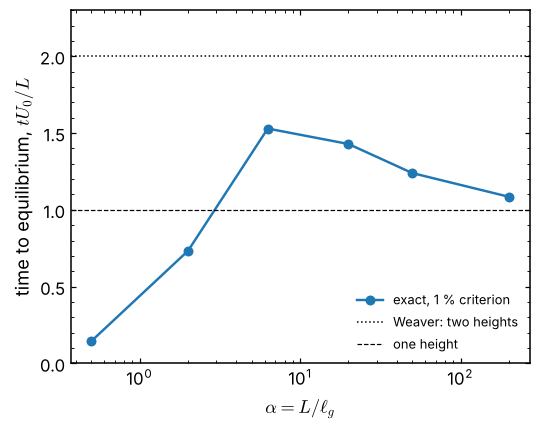

In [5]:
def settled_time(alpha, tol=0.01):
    zz = np.linspace(0, 1, 801)
    eq = alpha * np.exp(-alpha * zz) / -np.expm1(-alpha)
    if alpha <= 50:
        gap = lambda t: np.max(np.abs(on.mason_weaver(zz, t, alpha) - eq)) / eq.max() - tol
    else:
        edges = np.linspace(0, 1, 4001)
        times = np.linspace(0, 3, 601)
        zc, phi = on.sedimentation_fv(np.ones(4000), edges, times, alpha)
        eqc = alpha * np.exp(-alpha * zc) / -np.expm1(-alpha)
        g = np.array([np.max(np.abs(p - eqc)) for p in phi]) / eqc.max() - tol
        return times[np.argmax(g < 0)]
    return brentq(gap, 1e-3, 20)

rows = []
for alpha in (0.5, 2.0, 2 * math.pi, 20.0, 50.0, 200.0):
    rows.append((alpha, settled_time(alpha)))
    print(f"alpha = {alpha:6.2f}:  within 1 % after t = {rows[-1][1]:.3f} L/U0")

fig, ax = plt.subplots(figsize=(4.8, 3.8))
ax.semilogx([r[0] for r in rows], [r[1] for r in rows], "C0o-", label="exact, 1 % criterion")
ax.axhline(2, color="k", ls=":", lw=1, label="Weaver: two heights")
ax.axhline(1, color="k", ls="--", lw=0.8, label="one height")
ax.set_xlabel(r"$\alpha = L/\ell_g$"); ax.set_ylabel(r"time to equilibrium, $tU_0/L$")
ax.set_ylim(0, 2.3); ax.legend(loc="lower right", fontsize=8.5)
plt.show()

**Figure S10.1.** Time for a uniform suspension to come within 1 % of its equilibrium.

Weaver's rule is an upper bound, as he said. When gravity dominates ($\alpha$ large),
the time tends to one height, the time for the last particles to fall from the top
to the bottom; diffusion then needs only a short extra time to set up the thin
barometric layer. When diffusion dominates, equilibrium is reached faster than any
particle falls through the vessel, because the profile it must reach is nearly
uniform. The time is longest, about one and a half heights, near $\alpha = 2\pi$, where
the slowest rate $\lambda_1$ is smallest and neither process dominates.

## Exercise 4. An equation of state from a sedimentation profile

In the units of Eq. (10.12), Eq. (10.7) reads $d\tilde\Pi/dz = -\alpha\phi$, and with $\tilde\Pi = 0$ at the
top,

$$ \tilde\Pi(z) = \alpha\int_z^1\phi(z')\,dz' . $$

Each height gives a pair $(\phi(z), \tilde\Pi(z))$, a point of the equation of state.

   phi    recovered    Carnahan-Starling   ratio    d ln Pi / d ln phi
  0.010      0.0104       0.0103         1.015        1.04
  0.050      0.0606       0.0607         0.999        1.21
  0.101      0.1516       0.1542         0.983        1.44
  0.199      0.4855       0.4766         1.019        1.95
  0.299      1.1880       1.1788         1.008        2.57
  0.400      2.8413       2.7700         1.026        3.35
  0.480      5.5127       5.4770         1.007        4.15


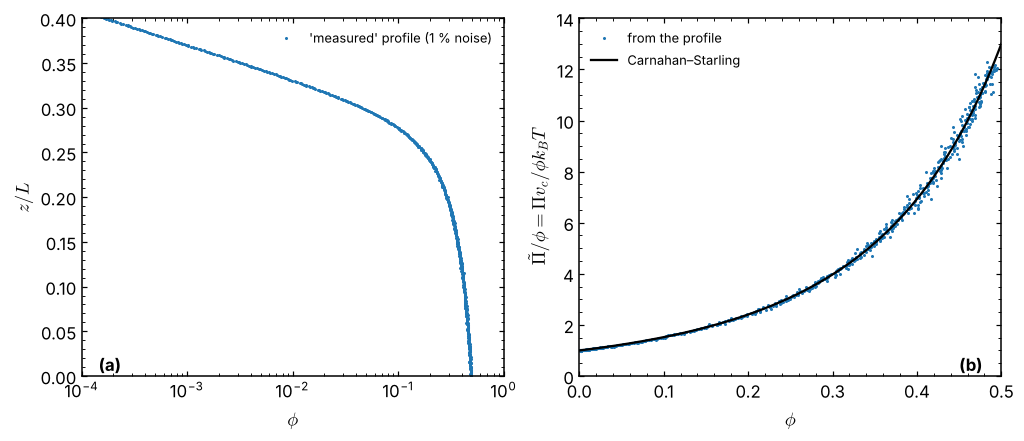

In [6]:
alpha, mean = 60.0, 0.1
zc = (np.arange(1600) + 0.5) / 1600

def equilibrium_profile(alpha, mean, z):
    def integrate(log_top):
        return solve_ivp(lambda s, y: [-alpha * y[0] / d_osmotic_cs(y[0])], (1, 0), [math.exp(log_top)],
                         dense_output=True, rtol=1e-11, atol=1e-14)
    def excess(log_top):
        zz = np.linspace(0, 1, 4001)
        return np.trapezoid(integrate(log_top).sol(zz)[0], zz) - mean
    return integrate(brentq(excess, -60, math.log(0.9))).sol(z)[0]

exact_profile = equilibrium_profile(alpha, mean, zc)
rng = np.random.default_rng(1)
measured = exact_profile * (1 + 0.01 * rng.standard_normal(zc.size))
dz = zc[1] - zc[0]
Pi = alpha * np.concatenate((np.cumsum((measured * dz)[::-1])[::-1][1:], [0.0]))   # weight of the particles above
Pi += alpha * 0.5 * measured * dz                                                 # half of the own cell

keep = measured > 1e-3
print("   phi    recovered    Carnahan-Starling   ratio    d ln Pi / d ln phi")
for p in (0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.48):
    i = np.argmin(np.abs(measured - p) + 10 * (~keep))
    q = measured[i]
    print(f"  {q:.3f}    {Pi[i]:8.4f}     {osmotic_cs(q):8.4f}         {Pi[i] / osmotic_cs(q):.3f}      {q * d_osmotic_cs(q) / osmotic_cs(q):6.2f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.9))
ax1.semilogx(measured, zc, "C0.", ms=2, label="'measured' profile (1 % noise)")
ax1.set_xlabel(r"$\phi$"); ax1.set_ylabel("$z/L$"); ax1.set_xlim(1e-4, 1); ax1.set_ylim(0, 0.4)
ax1.legend(loc="upper right", fontsize=8.5); on.panel_label(ax1, "(a)", x=0.04, y=0.06)
pp = np.linspace(1e-3, 0.5, 200)
ax2.plot(measured[keep], Pi[keep] / measured[keep], "C0.", ms=2, label="from the profile")
ax2.plot(pp, osmotic_cs(pp) / pp, "k-", lw=1.5, label="Carnahan–Starling")
ax2.set_xlabel(r"$\phi$"); ax2.set_ylabel(r"$\tilde\Pi/\phi = \Pi v_c/\phi k_BT$"); ax2.set_xlim(0, 0.5); ax2.set_ylim(0, 14)
ax2.legend(loc="upper left", fontsize=8.5); on.panel_label(ax2, "(b)", x=0.9, y=0.06)
plt.show()

**Figure S10.2.** **(a)** A sedimentation profile with 1 % noise. **(b)** The equation
of state recovered from it, as the compressibility factor $\tilde\Pi/\phi$.

The osmotic pressure itself is recovered well everywhere: it is an integral over
many measured points, and the noise averages out. The error comes from the other
coordinate, the measured volume fraction at the same height, which carries the full
1 % noise. How much that matters depends on how steep the equation of state is,
$d\ln\tilde\Pi/d\ln\phi$ (last column). In the dilute part this is close to 1, and a 1 % error
in $\phi$ is a 1 % error in the equation of state. Near $\phi = 0.48$ it is about 4: the
suspension there is nearly incompressible, its volume fraction hardly changes with
height, and a 1 % error in $\phi$ looks like a 4 % error in the pressure. The method is
therefore least accurate in the dense part of the sediment, which is the part of the
equation of state one most wants, and the volume fraction must be measured most
precisely there.